# Industrial Pump Anomaly Detection with an LSTM Autoencoder (Version 5)

**Goal.** Detect abnormal behaviour (faults, recovery periods, breakdowns) of an industrial water pump from its sensor readings alone.

**Approach.** An LSTM Autoencoder is trained on *normal* behaviour only. It learns to compress and rebuild windows of 30 consecutive sensor readings. A window that differs from normal behaviour is rebuilt poorly, so its **reconstruction error** is high. If the error exceeds a **threshold**, the window is flagged as an anomaly. No examples of faults are needed for training (unsupervised anomaly detection).

**Data.** `sensor.csv`: 220,320 readings from 51 sensors with a `machine_status` column (NORMAL, RECOVERING, BROKEN). Only about 6.6% of the readings are abnormal, and they are clustered in a few periods.

**What this notebook adds to a basic evaluation.** A single train/test split on a dataset with only a handful of fault events gives uncertain results. This notebook therefore evaluates the model in several complementary ways:

| Concern | How it is addressed |
|---|---|
| Very few fault events in one test set | **Block cross-validation:** every part of the data is used as test data exactly once (Section 13) |
| Block split does not look into the future | **Forward-chaining evaluation:** train on the past, test on later periods (Section 14) |
| Results change between training runs | **Ensemble of several seeds** and mean/standard deviation over runs (Sections 7-8) |
| Only one comparison method | **Six baselines:** Isolation Forest, PCA, One-Class SVM, dense autoencoder, GRU autoencoder, LSTM + Isolation Forest hybrid (Section 10) |

**What is new in version 5.** Version 4 showed that the model separates normal from abnormal windows well (AUC close to 0.99 in cross-validation), but that the *decision* is unstable: the F1-score varied strongly between folds, and the LSTM lost AUC when it was tested on later periods. Version 5 investigates the causes and adds measures against them:

| Finding in version 4 | Measure in version 5 | Section |
|---|---|---|
| The threshold was tuned with fault labels from only 2-3 validation events, which makes it unstable, and labels do not exist in deployment | **Label-free threshold:** a percentile of the error of *normal* validation windows (`THRESHOLD_Q`). It is reported next to the tuned threshold in every table (columns `LF ...`) and is the threshold used for deployment | 6, 8, 9, 13, 14 |
| F1 and precision depend strongly on the share of abnormal windows, which differs between test sets | Two prevalence-robust metrics are added: **PR-AUC** (average precision, `AP`) and **recall at a fixed false-alarm rate** (`Recall@FPR`) | 6 |
| Only 13 fault events exist, so differences between methods can be luck | **Block bootstrap** confidence intervals and paired differences | 10.2 |
| Many isolated false alarms | **Persistence rule** (alarm only if `k` of the last `m` windows exceed the threshold) | 11.2 |
| The LSTM lost AUC in forward chaining; drift was suspected but not shown | **Drift diagnosis**, and four drift-oriented variants tested in forward chaining: robust scaler, stable sensors only, first differences, adaptive threshold normalisation, plus an LSTM + Isolation Forest hybrid | 12.2, 14 |
| ReLU recurrent layers cannot use the fast GPU kernels and showed loss spikes | **tanh activation** (default of Keras recurrent layers) as the main setting; the ReLU model of version 4 is kept as an ablation | 6, 10 |
| The application needs more than a threshold | `config.json` now also stores the label-free threshold, the persistence rule and per-sensor reference statistics for a **drift monitor** | 9 |

**Contents**

| Section | Topic |
|---|---|
| 1-4 | Setup, data, exploration, first (baseline) version |
| 5-6 | Evaluation design (block split) and helper functions |
| 7-9 | LSTM ensemble: training, test evaluation, saving |
| 10 | Comparison with other methods, bootstrap confidence intervals |
| 11-12 | Event-level evaluation and persistence rule, sensor-level and drift diagnosis |
| 13-14 | Block cross-validation, forward-chaining evaluation with drift-oriented variants |
| 15 | Scalability (training data size, inference speed) |
| 16 | Summary and limitations |

**How to run.** Use *Runtime -> Change runtime type -> GPU*, then *Runtime -> Run all*. Several sections train many models, so the full run takes roughly one to one and a half hours on a T4 GPU (tanh recurrent layers train faster than the ReLU layers of version 4, but Section 14 now trains several model variants per step). All settings are in the configuration cell below; the run time can be shortened with `FC_VARIANTS`, `FC_CUTOFFS`, `SEEDS` and `RUN_RELU_ABLATION`.

## 1. Configuration and setup

All adjustable settings are collected in one place:
- `W`: window length (number of consecutive readings the model sees at once),
- `B`: block length used for splitting (Section 5),
- `STEP`: a new window starts every `STEP` readings,
- `EPOCHS`: maximum training epochs (early stopping usually ends training sooner),
- `RNN_ACTIVATION`: activation of the recurrent layers (`'tanh'` is the Keras default and allows fast GPU kernels; `'relu'` was used in version 4),
- `RUN_RELU_ABLATION`: also train the ReLU model of version 4 once, for comparison (Section 10),
- `SEEDS`: random seeds of the ensemble members (Section 7),
- `THRESHOLD_Q`: percentile of the error of normal validation windows used as the **label-free threshold**,
- `FPR_TARGET`: false-alarm rate (share of normal windows) used for the metric `Recall@FPR`,
- `PERSIST_M`, `PERSIST_K`, `PERSIST_GRID`: persistence rule (alarm if `PERSIST_K` of the last `PERSIST_M` windows exceed the threshold) and the settings shown for comparison (Section 11.2),
- `N_BOOT`: number of bootstrap resamples (Section 10.2),
- `TRAIN_FRACTIONS`: fractions of the training data used in the scalability check (Section 15),
- `K_FOLDS`: number of folds for block cross-validation (Section 13),
- `FC_CUTOFFS`, `FC_VAL_FRAC`, `FC_TEST_FRAC`, `FC_VARIANTS`: forward-chaining settings and the model variants compared (Section 14),
- `STABLE_Z`, `MIN_STABLE`: selection of stable sensors (a sensor is stable if the mean of its normal readings moves by less than `STABLE_Z` training standard deviations; at least `MIN_STABLE` sensors are always kept),
- `ROLL_WINDOWS`, `ADAPT_Q`: length of the recent history, and the quantile of it that is used as the current normal error level, for the adaptive threshold normalisation (Section 14),
- `SCALE_CLIP`: values of the robust scaler are clipped to +/- this limit,
- `PCA_COMPONENTS`, `OCSVM_SAMPLE`: settings of two baselines (Section 10).

In [1]:
DATA_PATH = '/content/drive/MyDrive/ML_Project/sensor.csv'
ARTIFACT_DIR = '/content/drive/MyDrive/ML_Project/artifacts/'

SEED = 42
W = 30                      # window length
B = 3000                    # block length
STEP = 3                    # stride between windows
EPOCHS = 30                 # maximum number of training epochs
BATCH_SIZE = 128
RNN_ACTIVATION = 'tanh'     # activation of the recurrent layers ('relu' = version 4)
RUN_RELU_ABLATION = True    # also train the ReLU model of version 4 once (Section 10)
SEEDS = [1, 2, 3]           # ensemble members / repeated runs

THRESHOLD_Q = 99            # label-free threshold: percentile of the error of normal validation windows
FPR_TARGET = 0.01           # false-alarm rate used for the metric Recall@FPR
PERSIST_M, PERSIST_K = 5, 3                         # persistence rule: K of the last M windows
PERSIST_GRID = [(1, 1), (2, 3), (3, 5), (5, 8)]     # (k, m) settings shown in Section 11.2
N_BOOT = 300                # bootstrap resamples (Section 10.2)

TRAIN_FRACTIONS = [0.25, 0.5]               # scalability check
K_FOLDS = 5                                 # block cross-validation
FC_CUTOFFS = [0.35, 0.45, 0.50]             # forward chaining: share of blocks used for training
FC_VAL_FRAC, FC_TEST_FRAC = 0.15, 0.15      # forward chaining: validation / test share
FC_VARIANTS = ['LSTM (baseline)', 'LSTM + robust scaler',
               'LSTM + stable sensors', 'LSTM + first differences']   # variants trained per step
STABLE_Z, MIN_STABLE = 1.0, 10              # stable-sensor selection
ROLL_WINDOWS = 1000                         # history length of the adaptive threshold normalisation
ADAPT_Q = 0.25                              # quantile of the recent history used as reference level
SCALE_CLIP = 10.0                           # clipping limit of the robust scaler
PCA_COMPONENTS = 20
OCSVM_SAMPLE = 5000

This cell imports the libraries, fixes the random seed for reproducibility and mounts Google Drive, where the dataset and the saved artifacts are stored.

In [2]:
import os
import json
import time
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (LSTM, GRU, Dense, RepeatVector, TimeDistributed,
                                     Input, Flatten, Reshape)
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

tf.keras.utils.set_random_seed(SEED)

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Not running in Colab: Google Drive was not mounted.")

print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)

Mounted at /content/drive
GPU available: True


## 2. Data loading and cleaning

This cell loads the data and prepares it for modelling:
- removes columns without useful information (`sensor_15`, the index column),
- converts `timestamp` to a date-time type and sorts the rows chronologically,
- fills missing sensor values (forward fill, then backward fill),
- creates a binary `label`: **0 = NORMAL**, **1 = abnormal** (RECOVERING or BROKEN),
- collects the names of all sensor columns.

Scaling is deliberately **not** done here. It is done separately for every split using training data only, to avoid data leakage.

In [3]:
df = pd.read_csv(DATA_PATH)

df.drop(['sensor_15', 'Unnamed: 0'], axis=1, inplace=True, errors='ignore')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df.sort_values('timestamp', inplace=True)
df = df.ffill().bfill()

df['label'] = df['machine_status'].apply(lambda x: 0 if x == 'NORMAL' else 1)

sensor_cols = [c for c in df.columns if 'sensor' in c]
print("Total records:", len(df), "| number of sensors:", len(sensor_cols))

Total records: 220320 | number of sensors: 51


## 3. Data exploration

### 3.1 Class balance

Number of readings per machine status. Anomaly data is strongly imbalanced, which is why plain accuracy is a misleading metric in this project: a model that always predicts "normal" would already reach about 93% accuracy.

In [4]:
print(df['machine_status'].value_counts())
print()
print(df['label'].value_counts(normalize=True))

machine_status
NORMAL        205836
RECOVERING     14477
BROKEN             7
Name: count, dtype: int64

label
0    0.934259
1    0.065741
Name: proportion, dtype: float64


### 3.2 Where does the abnormal data sit in time?

The dataset is divided into 10 equal time segments and the share of abnormal readings is printed for each. This shows whether abnormal events are spread evenly or clustered, which determines how the data can be split safely.

In [5]:
pos = np.where(df['label'].values == 1)[0]
print("First abnormal row:", pos.min(), "| Last abnormal row:", pos.max(), "| Total rows:", len(df))

n_seg = 10
seg_size = len(df) // n_seg
for s in range(n_seg):
    part = df['label'].values[s * seg_size:(s + 1) * seg_size]
    print(f"Segment {s + 1}/{n_seg}: abnormal = {part.mean() * 100:.1f}%")

First abnormal row: 17155 | Last abnormal row: 166515 | Total rows: 220320
Segment 1/10: abnormal = 4.3%
Segment 2/10: abnormal = 14.1%
Segment 3/10: abnormal = 0.0%
Segment 4/10: abnormal = 8.7%
Segment 5/10: abnormal = 0.0%
Segment 6/10: abnormal = 18.8%
Segment 7/10: abnormal = 19.4%
Segment 8/10: abnormal = 0.3%
Segment 9/10: abnormal = 0.0%
Segment 10/10: abnormal = 0.0%


## 4. Baseline results (first version)

The first version of the project trained the autoencoder on the first 30,000 normal rows only, set the threshold to `mean + 3 x standard deviation` of the training error, fitted the scaler on all normal rows of the dataset, and evaluated on the whole dataset.

| Metric (abnormal class) | First version |
|---|---|
| Precision | 0.08 |
| Recall | 0.99 |
| Accuracy | 0.28 |
| False alarms | about 158,200 normal windows flagged as abnormal |

**Interpretation.** The model flagged almost every window as abnormal. Recall was high only because nearly everything raised an alarm.

**Likely causes.** (1) The model saw only the first 30,000 normal readings, whereas normal pump behaviour drifts over time. (2) The threshold was calibrated on that narrow data. (3) The scaler was fitted on rows from the whole dataset, which is data leakage.

The remaining sections replace this setup with a proper evaluation design.

## 5. Evaluation design: block-based split

A simple chronological split (60/20/20) does not work here, because abnormal data is clustered in the middle of the timeline: the validation and test parts contained **no abnormal readings at all**.

The data is therefore cut into **blocks** of `B` consecutive rows:
- every block belongs entirely to one set (train, validation or test), so overlapping windows of the same event never appear in two sets,
- blocks containing only normal data are divided 60/20/20, and blocks containing abnormal data are divided 20/40/40, so that validation and test both contain abnormal cases,
- windows of `W` readings are built inside each block; a window is labelled abnormal if any of its rows is abnormal.

The function `prepare` builds the three sets for any choice of blocks and always fits the scaler on **normal rows of the training blocks only**. It is reused by the cross-validation and forward-chaining sections. Version 5 extends it with three options used in Section 14: the type of scaler (`'minmax'` or `'robust'`), a subset of sensors, and first differences (`diff=True`, the change between consecutive readings, which removes slow drifts). It also marks windows that contain a BROKEN reading, so that breakdowns can be reported separately (Section 11.3).

The model is trained, and the threshold is chosen, without ever using the test set.

In [6]:
n = len(df)
labels = df['label'].values
is_broken = (df['machine_status'] == 'BROKEN').values
values = df[sensor_cols].values
n_blocks = n // B
blk_has_abn = np.array([labels[b * B:(b + 1) * B].max() for b in range(n_blocks)])
N_FEATURES = len(sensor_cols)

SCALERS = {'minmax': MinMaxScaler, 'robust': RobustScaler}

def block_rows(blocks):
    return np.concatenate([np.arange(b * B, (b + 1) * B) for b in blocks])

def prepare(train_blocks, val_blocks, test_blocks, scaler='minmax', sensors=None, diff=False):
    """Scale (fitted on normal training rows only) and cut windows for the three sets.

    scaler : 'minmax' or 'robust' (median / interquartile range, clipped to +/- SCALE_CLIP)
    sensors: optional array of sensor indices to keep
    diff   : use first differences (change between consecutive readings) instead of raw values
    """
    rows = block_rows(train_blocks)
    rows = rows[labels[rows] == 0]
    x = values if sensors is None else values[:, sensors]
    if diff:
        x = np.diff(x, axis=0, prepend=x[:1])
    scaler_ = SCALERS[scaler]().fit(x[rows])
    scaled = scaler_.transform(x)
    if scaler == 'robust':
        scaled = np.clip(scaled, -SCALE_CLIP, SCALE_CLIP)
    scaled = scaled.astype(np.float32)

    def windows(blocks):
        Xs, ys, gs, bs = [], [], [], []
        for b in blocks:
            for i in range(b * B, (b + 1) * B - W + 1, STEP):
                Xs.append(scaled[i:i + W])
                ys.append(labels[i:i + W].max())          # abnormal if any row of the window is abnormal
                gs.append(b)
                bs.append(is_broken[i:i + W].max())       # window contains a BROKEN reading
        return (np.array(Xs, dtype=np.float32), np.array(ys), np.array(gs), np.array(bs, dtype=bool))

    out = {'scaler': scaler_, 'fit_rows': rows}
    for key, blocks in [('tr', train_blocks), ('va', val_blocks), ('te', test_blocks)]:
        out['X_' + key], out['y_' + key], out['g_' + key], out['b_' + key] = windows(blocks)
    return out

# Primary split (same procedure as in earlier versions of this project)
rng = np.random.default_rng(SEED)

def split_blocks(ids, fractions):
    ids = rng.permutation(ids)
    a = int(len(ids) * fractions[0])
    b = a + int(len(ids) * fractions[1])
    return ids[:a], ids[a:b], ids[b:]

tr_n, va_n, te_n = split_blocks(np.where(blk_has_abn == 0)[0], (0.6, 0.2))   # normal blocks:   60/20/20
tr_a, va_a, te_a = split_blocks(np.where(blk_has_abn == 1)[0], (0.2, 0.4))   # abnormal blocks: 20/40/40

D = prepare(np.concatenate([tr_n, tr_a]), np.concatenate([va_n, va_a]), np.concatenate([te_n, te_a]))
sc = D['scaler']
X_tr, y_tr, g_tr = D['X_tr'], D['y_tr'], D['g_tr']
X_va, y_va, g_va = D['X_va'], D['y_va'], D['g_va']
X_te, y_te, g_te = D['X_te'], D['y_te'], D['g_te']

X_tr_n = X_tr[y_tr == 0]    # the model learns from normal windows only
X_va_n = X_va[y_va == 0]

print("Blocks:", n_blocks, "| blocks containing abnormal data:", int(blk_has_abn.sum()))
print("Train (normal only):", X_tr_n.shape)
print("Validation:", X_va.shape, "| abnormal windows: %.1f%%" % (y_va.mean() * 100))
print("Test:      ", X_te.shape, "| abnormal windows: %.1f%%" % (y_te.mean() * 100))
print("Windows containing a BROKEN reading (validation / test):", int(D['b_va'].sum()), "/", int(D['b_te'].sum()))

Blocks: 73 | blocks containing abnormal data: 13
Train (normal only): (37169, 30, 51)
Validation: (16847, 30, 51) | abnormal windows: 17.6%
Test:       (17838, 30, 51) | abnormal windows: 7.8%
Windows containing a BROKEN reading (validation / test): 20 / 40


## 6. Models and helper functions

This cell defines the models and the functions used for evaluation throughout the notebook.

**Models**
- `build_model`: a deep **autoencoder** with recurrent layers (`cell='LSTM'` is the main model, `cell='GRU'` a comparison model). The encoder (128 -> 64 units) compresses a window into a small summary vector, `RepeatVector` expands it back to `W` steps, and the decoder (64 -> 128 units -> Dense) rebuilds the original window. Training minimises the mean squared error (MSE) between input and output. The activation of the recurrent layers is `RNN_ACTIVATION` (`'tanh'` by default) and can be overridden per model.
- `build_dense_ae`: a simpler autoencoder that ignores the time order and uses only fully connected layers.
- `train_ae`: trains an autoencoder on normal windows with early stopping (training stops when the validation loss has not improved for 5 epochs, and the best weights are restored).

**Scoring and thresholds**
- `get_err`: reconstruction error (mean absolute error) of every window; a high error means the window looks unlike normal behaviour.
- `pick_threshold`: the **tuned threshold**: the value with the highest F1-score on the validation set. It uses fault labels.
- `label_free_threshold`: the **label-free threshold**: the `THRESHOLD_Q`-th percentile of the error of *normal* validation windows. By construction about `100 - THRESHOLD_Q` percent of normal windows raise an alarm. Only the information "these windows are healthy" is needed, which in practice is available from a commissioning or maintenance period. This is the threshold used for deployment.
- `summarize`: all window-level metrics on the test set, for both thresholds, with thresholds always chosen on the validation set.
- `persistence_alarms`: persistence rule (Section 11.2).
- `adaptive_scores`, `robust_standardise`, `standardised_average`: score transformations used for the adaptive threshold and the hybrid model (Section 14).
- `find_runs`, `event_report`, `evaluate_alarms`: event-level evaluation (Section 11).
- `sensor_drift`, `stable_sensor_idx`: drift diagnosis and stable-sensor selection (Sections 12.2 and 14).
- `block_bootstrap`: confidence intervals over blocks (Section 10.2).

**Metric definitions.** *Precision*: of all alarms raised, the share that were real anomalies. *Recall*: of all real anomalies, the share that were detected. *F1*: the balance of precision and recall. *AUC*: how well the scores separate normal from abnormal windows regardless of the threshold (0.5 = guessing, 1.0 = perfect). Two metrics are added in version 5 because precision and F1 depend strongly on how many abnormal windows a test set contains (7.8% in the primary test set, below 1% in some forward-chaining steps): **AP** (average precision, the area under the precision-recall curve; its baseline is the share of abnormal windows) and **Recall@FPR** (the share of abnormal windows detected when `FPR_TARGET` of the normal windows may raise a false alarm, which does not depend on the share of abnormal windows). Columns starting with **LF** use the label-free threshold; columns without prefix use the tuned threshold.

In [7]:
def build_model(w, n_features, cell='LSTM', activation=None):
    activation = activation or RNN_ACTIVATION
    Rnn = LSTM if cell == 'LSTM' else GRU
    m = Sequential([
        Input(shape=(w, n_features)),
        Rnn(128, activation=activation, return_sequences=True),
        Rnn(64, activation=activation, return_sequences=False),
        RepeatVector(w),
        Rnn(64, activation=activation, return_sequences=True),
        Rnn(128, activation=activation, return_sequences=True),
        TimeDistributed(Dense(n_features))
    ])
    m.compile(optimizer='adam', loss='mse')
    return m

def build_dense_ae(w, n_features):
    m = Sequential([
        Input(shape=(w, n_features)),
        Flatten(),
        Dense(256, activation='relu'),
        Dense(64, activation='relu'),
        Dense(256, activation='relu'),
        Dense(w * n_features),
        Reshape((w, n_features))
    ])
    m.compile(optimizer='adam', loss='mse')
    return m

def train_ae(builder, X_train, X_val, seed, verbose=0):
    """Train an autoencoder; returns the model, its history and the training time in seconds."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    m = builder()
    stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    t0 = time.time()
    h = m.fit(X_train, X_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
              validation_data=(X_val, X_val), callbacks=[stop], verbose=verbose)
    return m, h, time.time() - t0

def get_err(m, X):
    """Reconstruction error (MAE) of every window."""
    p = m.predict(X, batch_size=256, verbose=0)
    return np.mean(np.abs(p - X), axis=(1, 2))

# ---- thresholds and window-level metrics -------------------------------------------------
def pick_threshold(y_val, val_scores, return_f1=False):
    """Tuned threshold: highest F1-score on the validation set (uses fault labels)."""
    p, r, t = precision_recall_curve(y_val, val_scores)
    f1 = (2 * p * r / (p + r + 1e-9))[:-1]
    i = int(np.argmax(f1))
    return (t[i], f1[i]) if return_f1 else t[i]

def label_free_threshold(y_val, val_scores, q=None):
    """Label-free threshold: q-th percentile of the scores of normal validation windows."""
    q = THRESHOLD_Q if q is None else q
    return float(np.percentile(val_scores[y_val == 0], q))

def recall_at_fpr(y, scores, fpr=None):
    """Share of abnormal windows detected when `fpr` of the normal windows may raise an alarm."""
    fpr = FPR_TARGET if fpr is None else fpr
    f, t, _ = roc_curve(y, scores)
    return float(np.interp(fpr, f, t))

def summarize(name, y_val, val_scores, y_test, test_scores):
    thr_, val_f1 = pick_threshold(y_val, val_scores, return_f1=True)
    thr_lf = label_free_threshold(y_val, val_scores)
    pred = (test_scores > thr_).astype(int)
    pred_lf = (test_scores > thr_lf).astype(int)
    return {'Model': name,
            'AUC': roc_auc_score(y_test, test_scores),
            'AP': average_precision_score(y_test, test_scores),
            'Recall@FPR': recall_at_fpr(y_test, test_scores),
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred, zero_division=0),
            'F1': f1_score(y_test, pred, zero_division=0),
            'LF Precision': precision_score(y_test, pred_lf, zero_division=0),
            'LF Recall': recall_score(y_test, pred_lf, zero_division=0),
            'LF F1': f1_score(y_test, pred_lf, zero_division=0),
            'Threshold': thr_, 'LF Threshold': thr_lf, 'Validation F1': val_f1}

METRIC_COLS = ['AUC', 'AP', 'Recall@FPR', 'Precision', 'Recall', 'F1', 'LF Precision', 'LF Recall', 'LF F1']

# ---- events, persistence ----------------------------------------------------------------------
def find_runs(mask):
    """Start and end index of every run of consecutive True values."""
    runs, start = [], None
    for i, v in enumerate(mask):
        if v and start is None:
            start = i
        if (not v) and start is not None:
            runs.append((start, i - 1))
            start = None
    if start is not None:
        runs.append((start, len(mask) - 1))
    return runs

def event_report(y, alarms, groups):
    """Event-level results: an event is a run of abnormal windows inside one block."""
    alarms = np.asarray(alarms, dtype=bool)
    events, false_episodes = [], 0
    for b in np.unique(groups):
        idx = np.where(groups == b)[0]
        yb, ab = y[idx], alarms[idx]
        for s, e in find_runs(yb == 1):
            hit = np.where(ab[s:e + 1])[0]
            events.append({'Block': b, 'Event length (windows)': e - s + 1,
                           'Detected': bool(len(hit)),
                           'Delay (readings)': hit[0] * STEP if len(hit) else np.nan})
        false_episodes += len(find_runs((yb == 0) & ab))
    ev = pd.DataFrame(events)
    summary = {'Events': len(ev),
               'Detected': int(ev['Detected'].sum()) if len(ev) else 0,
               'Detection rate': float(ev['Detected'].mean()) if len(ev) else np.nan,
               'Median delay (readings)': float(ev['Delay (readings)'].median()) if len(ev) else np.nan,
               'False-alarm episodes': false_episodes}
    return ev, summary

def persistence_alarms(alarms, groups, m, k):
    """Persistence rule: alarm only if at least k of the last m windows of the same block exceeded the threshold."""
    alarms = np.asarray(alarms, dtype=bool)
    out = np.zeros(len(alarms), dtype=bool)
    for g in np.unique(groups):
        idx = np.where(groups == g)[0]
        count = np.convolve(alarms[idx].astype(int), np.ones(m, dtype=int))[:len(idx)]
        out[idx] = count >= k
    return out

def evaluate_alarms(name, y, alarms, groups):
    """Window-level and event-level results of one set of alarms."""
    alarms = np.asarray(alarms, dtype=bool)
    _, s = event_report(y, alarms, groups)
    return {'Setup': name,
            'Precision': precision_score(y, alarms, zero_division=0),
            'Recall': recall_score(y, alarms, zero_division=0),
            'F1': f1_score(y, alarms, zero_division=0), **s}

def result_fields(r, ev):
    """Columns shared by the cross-validation and forward-chaining tables."""
    return {'AUC': r['AUC'], 'AP': r['AP'], 'Recall@FPR': r['Recall@FPR'],
            'Precision': r['Precision'], 'Recall': r['Recall'], 'F1': r['F1'],
            'LF Precision': r['LF Precision'], 'LF Recall': r['LF Recall'], 'LF F1': r['LF F1'],
            'Events': ev['Events'], 'Detected': ev['Detected'],
            'False-alarm episodes': ev['False-alarm episodes']}

# ---- features, score transformations ----------------------------------------------------------
def window_features(X):
    """Summary statistics per sensor (mean, std, min, max): 4 x number of sensors features per window."""
    return np.concatenate([X.mean(axis=1), X.std(axis=1), X.min(axis=1), X.max(axis=1)], axis=1)

def robust_standardise(ref, scores):
    """Centre and scale scores with the median and MAD of a reference set (normal validation windows)."""
    med = np.median(ref)
    mad = np.median(np.abs(ref - med)) * 1.4826 + 1e-9
    return (scores - med) / mad

def standardised_average(sets, y_val):
    """Average of robust z-scores of several models. `sets` = [(validation scores, test scores), ...].
    Every model is standardised with the normal validation windows of its own scores."""
    va = np.mean([robust_standardise(v[y_val == 0], v) for v, _ in sets], axis=0)
    te = np.mean([robust_standardise(v[y_val == 0], t) for v, t in sets], axis=0)
    return va, te

def adaptive_scores(scores, history, R=None):
    """Divide every score by the lower quartile (ADAPT_Q) of the previous R scores (causal rolling quantile).
    `history` = scores that came before `scores` in time. Adapts the threshold to slow drift of the error level.
    A low quantile is used so that long abnormal periods do not raise the reference level."""
    R = ROLL_WINDOWS if R is None else R
    hist = np.asarray(history)[-R:]
    s = np.concatenate([hist, scores])
    med = pd.Series(s).rolling(R, min_periods=1).quantile(ADAPT_Q).values[len(hist):]
    return scores / (med + 1e-9)

# ---- drift ---------------------------------------------------------------------------------------
def sensor_drift(ref_rows, new_rows):
    """Per sensor: shift of the mean of `new_rows` relative to `ref_rows`, in standard deviations of `ref_rows`,
    and the share of `new_rows` readings outside the range seen in `ref_rows`."""
    ref, new = values[ref_rows], values[new_rows]
    mu, sd = ref.mean(axis=0), ref.std(axis=0)
    ok = sd > 1e-6
    shift = np.where(ok, (new.mean(axis=0) - mu) / np.where(ok, sd, 1.0), 0.0)
    outside = ((new < ref.min(axis=0)) | (new > ref.max(axis=0))).mean(axis=0) * 100
    return pd.DataFrame({'Shift (std units)': shift, 'Out of range (%)': outside}, index=sensor_cols)

def stable_sensor_idx(train_blocks, val_blocks):
    """Indices of sensors whose normal readings barely move between the training and the validation blocks."""
    tr = block_rows(train_blocks)
    tr = tr[labels[tr] == 0]
    va = block_rows(val_blocks)
    va = va[labels[va] == 0]
    if len(va) == 0:
        return np.arange(N_FEATURES)
    shift = sensor_drift(tr, va)['Shift (std units)'].abs().values
    keep = np.where(shift < STABLE_Z)[0]
    if len(keep) < MIN_STABLE:
        keep = np.sort(np.argsort(shift)[:MIN_STABLE])
    return keep

# ---- bootstrap -----------------------------------------------------------------------------------
def block_bootstrap(y, groups, score_dict, thresholds, n_boot=None, seed=None):
    """Resample the test blocks with replacement. Returns {model: array (resamples, 3)} with AUC, AP and
    label-free F1. All models use the same resamples, so differences between models are paired."""
    n_boot = N_BOOT if n_boot is None else n_boot
    r = np.random.default_rng(SEED if seed is None else seed)
    blocks = np.unique(groups)
    idx_of = {b: np.where(groups == b)[0] for b in blocks}
    out = {k: [] for k in score_dict}
    for _ in range(n_boot):
        pick = r.choice(blocks, size=len(blocks), replace=True)
        idx = np.concatenate([idx_of[b] for b in pick])
        yb = y[idx]
        if yb.min() == yb.max():
            continue
        for k, s in score_dict.items():
            sb = s[idx]
            out[k].append([roc_auc_score(yb, sb), average_precision_score(yb, sb),
                           f1_score(yb, sb > thresholds[k], zero_division=0)])
    return {k: np.array(v) for k, v in out.items()}

## 7. Training the LSTM ensemble

Neural networks start from random weights, so two training runs of the same code give slightly different results, and a single run can be too optimistic or too pessimistic. Instead of relying on one run, one LSTM Autoencoder is trained for every seed in `SEEDS`, on the same data split. This gives:
- the **spread** of the results over runs (mean and standard deviation, Section 8),
- an **ensemble**: the reconstruction errors of all members are averaged, which makes the scores more stable,
- a **selected model** for deployment: the member with the best F1-score on the *validation* set (never chosen using the test set).

The training time of every member is recorded for the scalability analysis in Section 15.

Seed 1: 30 epochs, 147 s, validation F1 = 0.931
Seed 2: 30 epochs, 145 s, validation F1 = 0.945
Seed 3: 30 epochs, 144 s, validation F1 = 0.948


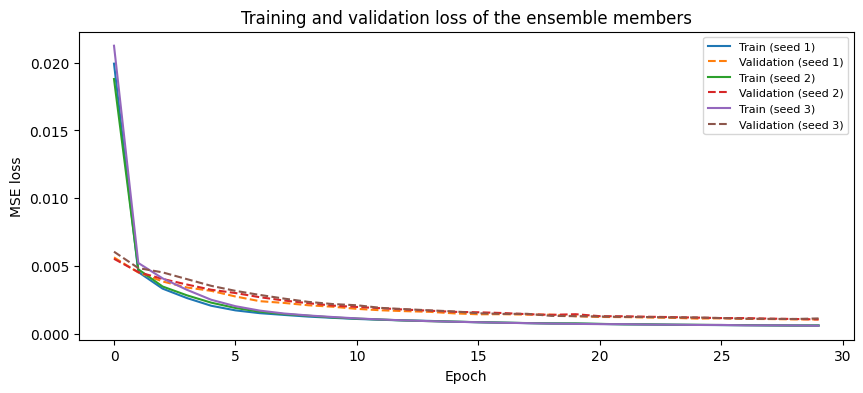

In [8]:
members = []
for seed in SEEDS:
    m, h, secs = train_ae(lambda: build_model(W, N_FEATURES), X_tr_n, X_va_n, seed, verbose=0)
    va_e, te_e = get_err(m, X_va), get_err(m, X_te)
    r = summarize(f'LSTM (seed {seed})', y_va, va_e, y_te, te_e)
    members.append({'seed': seed, 'model': m, 'history': h, 'seconds': secs,
                    'va_err': va_e, 'te_err': te_e, 'result': r})
    print(f"Seed {seed}: {len(h.history['loss'])} epochs, {secs:.0f} s, validation F1 = {r['Validation F1']:.3f}")

plt.figure(figsize=(10, 4))
for mem in members:
    plt.plot(mem['history'].history['loss'], label=f"Train (seed {mem['seed']})")
    plt.plot(mem['history'].history['val_loss'], linestyle='--', label=f"Validation (seed {mem['seed']})")
plt.title('Training and validation loss of the ensemble members')
plt.xlabel('Epoch')
plt.ylabel('MSE loss')
plt.legend(fontsize=8)
plt.show()

## 8. Evaluation on the test set

The test set was never used for training or for choosing thresholds. The table lists every ensemble member, the **ensemble** (average of the members' errors) and the **selected model** (best validation F1). Two thresholds are compared, both chosen on the validation set only:
1. the **tuned threshold**: the value giving the best F1-score on validation (needs fault labels),
2. the **label-free threshold**: the `THRESHOLD_Q`-th percentile of the error of normal validation windows (needs no fault labels, used for deployment and for all later event-level results).

Confusion matrices and classification reports are shown for the ensemble with both thresholds.

In [9]:
ens_va = np.mean([mem['va_err'] for mem in members], axis=0)
ens_te = np.mean([mem['te_err'] for mem in members], axis=0)
ens_result = summarize('LSTM ensemble', y_va, ens_va, y_te, ens_te)
thr_ens, thr_lf_ens = ens_result['Threshold'], ens_result['LF Threshold']

member_df = pd.DataFrame([mem['result'] for mem in members])
sel_idx = int(member_df['Validation F1'].values.argmax())
selected = members[sel_idx]
model = selected['model']                         # selected model (used for deployment)
te_err = selected['te_err']
thr = selected['result']['Threshold']             # tuned threshold of the selected model
thr_sel_lf = selected['result']['LF Threshold']   # label-free threshold of the selected model (deployed)

print(member_df[['Model'] + METRIC_COLS + ['Validation F1']].round(3).to_string(index=False))
print(f"\nSelected member (best validation F1): seed {selected['seed']}")
print("\nMean and standard deviation over members:")
print(member_df[METRIC_COLS].agg(['mean', 'std']).round(3))
print("\nEnsemble:", {k: round(float(v), 3) for k, v in ens_result.items() if k != 'Model'})

for name, t_ in [("tuned (best F1 on validation)", thr_ens),
                 (f"label-free ({THRESHOLD_Q}th percentile of normal validation error)", thr_lf_ens)]:
    y_pred = (ens_te > t_).astype(int)
    print(f"\n=== Ensemble, threshold: {name} = {t_:.4f} ===")
    print(confusion_matrix(y_te, y_pred))
    print(classification_report(y_te, y_pred, target_names=['Normal', 'Abnormal'], digits=2, zero_division=0))

        Model   AUC    AP  Recall@FPR  Precision  Recall    F1  LF Precision  LF Recall  LF F1  Validation F1
LSTM (seed 1) 0.981 0.732       0.518      0.685   0.688 0.686         0.653      0.767  0.705          0.931
LSTM (seed 2) 0.981 0.716       0.493      0.649   0.825 0.727         0.655      0.914  0.763          0.945
LSTM (seed 3) 0.983 0.732       0.507      0.640   0.974 0.772         0.650      0.971  0.779          0.948

Selected member (best validation F1): seed 3

Mean and standard deviation over members:
        AUC     AP  Recall@FPR  Precision  Recall     F1  LF Precision  \
mean  0.982  0.726       0.506      0.658   0.829  0.728         0.652   
std   0.001  0.009       0.012      0.024   0.143  0.043         0.003   

      LF Recall  LF F1  
mean      0.884  0.749  
std       0.105  0.039  

Ensemble: {'AUC': 0.982, 'AP': 0.726, 'Recall@FPR': 0.513, 'Precision': 0.663, 'Recall': 0.975, 'F1': 0.789, 'LF Precision': 0.665, 'LF Recall': 0.952, 'LF F1': 0.783, 'Thr

### 8.1 Reconstruction error on the test set

Ensemble reconstruction error of every test window, coloured by its true label, with both thresholds. A good model keeps normal windows below the line and abnormal windows above it.

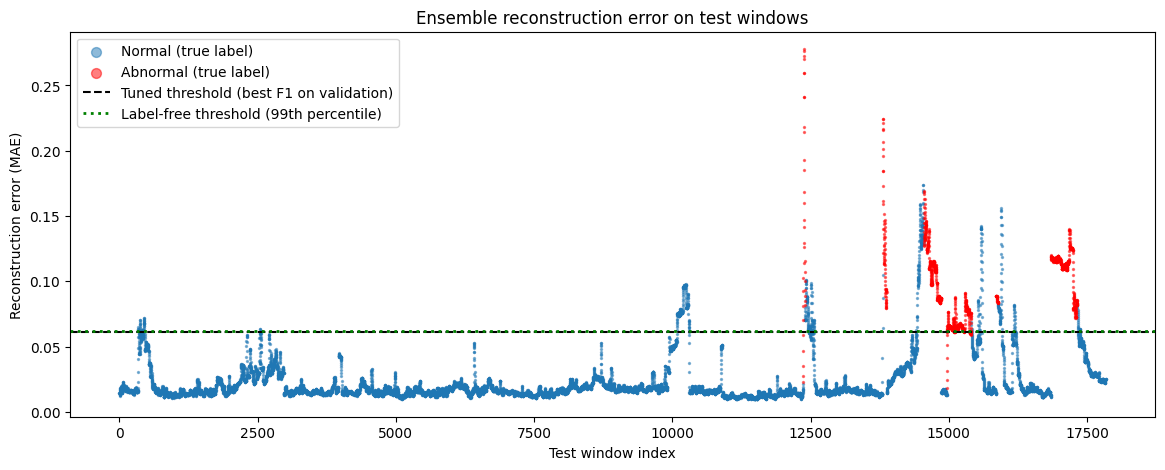

In [10]:
plt.figure(figsize=(14, 5))
idx = np.arange(len(ens_te))
plt.scatter(idx[y_te == 0], ens_te[y_te == 0], s=2, alpha=0.5, label='Normal (true label)')
plt.scatter(idx[y_te == 1], ens_te[y_te == 1], s=2, alpha=0.5, color='red', label='Abnormal (true label)')
plt.axhline(thr_ens, color='black', linestyle='--', label='Tuned threshold (best F1 on validation)')
plt.axhline(thr_lf_ens, color='green', linestyle=':', linewidth=2, label=f'Label-free threshold ({THRESHOLD_Q}th percentile)')
plt.title('Ensemble reconstruction error on test windows')
plt.xlabel('Test window index')
plt.ylabel('Reconstruction error (MAE)')
plt.legend(markerscale=5)
plt.show()

## 9. Saving model artifacts

Everything needed to use the selected model outside this notebook (for example in a monitoring application) is saved:
- the trained model (`.keras`, the recommended Keras format),
- the fitted scaler (the same scaling must be applied to new sensor data),
- a JSON file with
  - the **label-free threshold** of the selected model (the deployed threshold) and, for reference, the tuned threshold,
  - the persistence rule (`k` of the last `m` windows), the window length, the stride and the ordered list of sensor columns,
  - the **reference statistics for a drift monitor**: the mean and standard deviation of every sensor over the normal training rows, and the median and 99th percentile of the reconstruction error of normal validation windows. An application can compare recent normal-looking data with these values; when sensors move by several standard deviations or the typical error rises, the model or the threshold should be recalibrated.

In [11]:
os.makedirs(ARTIFACT_DIR, exist_ok=True)

fit_rows = D['fit_rows']                                  # normal training rows used to fit the scaler
normal_val_err = selected['va_err'][y_va == 0]

config = {
    'threshold': float(thr_sel_lf),
    'threshold_type': f'label-free: {THRESHOLD_Q}th percentile of the reconstruction error of normal validation windows',
    'threshold_tuned_f1': float(thr),
    'persistence': {'k': PERSIST_K, 'm': PERSIST_M},
    'window_length': W,
    'stride': STEP,
    'recurrent_activation': RNN_ACTIVATION,
    'scaler': type(sc).__name__,
    'sensor_columns': sensor_cols,
    'selected_seed': int(selected['seed']),
    'reference_statistics': {
        'sensor_mean': values[fit_rows].mean(axis=0).tolist(),
        'sensor_std': values[fit_rows].std(axis=0).tolist(),
        'normal_error_median': float(np.median(normal_val_err)),
        'normal_error_p99': float(np.percentile(normal_val_err, 99)),
    },
}

model.save(os.path.join(ARTIFACT_DIR, 'lstm_autoencoder.keras'))
joblib.dump(sc, os.path.join(ARTIFACT_DIR, 'scaler.joblib'))
with open(os.path.join(ARTIFACT_DIR, 'config.json'), 'w') as f:
    json.dump(config, f, indent=2)

print("Saved to:", ARTIFACT_DIR, "->", os.listdir(ARTIFACT_DIR))
print("Deployed threshold (label-free): %.4f | tuned threshold (reference): %.4f" % (thr_sel_lf, thr))

Saved to: /content/drive/MyDrive/ML_Project/artifacts/ -> ['lstm_autoencoder.keras', 'scaler.joblib', 'config.json']
Deployed threshold (label-free): 0.0598 | tuned threshold (reference): 0.0585


## 10. Comparison with other methods

To check whether the LSTM Autoencoder is actually necessary, it is compared with other methods. All of them are trained on the same normal training windows, scored on the same test windows, and use thresholds chosen on the same validation set, so the comparison is fair.

| Method | Idea |
|---|---|
| **Isolation Forest** | Isolates unusual points with random decision trees: the fewer cuts needed to isolate a point, the more abnormal it is. |
| **PCA reconstruction error** | Compresses a flattened window to `PCA_COMPONENTS` linear components and measures how badly it is rebuilt. A linear counterpart of an autoencoder. |
| **One-Class SVM** | Learns a boundary around normal data; points outside it are abnormal. Trained on a random subset of `OCSVM_SAMPLE` windows because it is slow on large data. |
| **Dense autoencoder** | An autoencoder with fully connected layers only, which ignores the order of readings. |
| **GRU autoencoder** | Same structure as the LSTM autoencoder with GRU cells, a lighter recurrent unit. |
| **LSTM + Isolation Forest** | Average of the standardised scores of the LSTM ensemble and the Isolation Forest (every score is centred and scaled with the normal validation windows of its own model). The two methods look at the data differently: the LSTM at the sequence, the Isolation Forest at summary statistics. |
| **LSTM (ReLU, as in version 4)** | Single run of the LSTM autoencoder with ReLU activation, only to show the effect of the activation change (`RUN_RELU_ABLATION`). |

Isolation Forest and One-Class SVM cannot read a `W x 51` window directly, so every window is summarised by the four statistics per sensor (mean, standard deviation, minimum, maximum). The other methods are single runs (seed `SEED`); the LSTM is shown as the ensemble and as the mean of its members.

In [12]:
F_tr, F_va, F_te = window_features(X_tr_n), window_features(X_va), window_features(X_te)
score_sets = {'LSTM ensemble': (ens_va, ens_te)}      # name -> (validation scores, test scores)

# 1. Isolation Forest
iso = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(F_tr)
iso_va, iso_te = -iso.score_samples(F_va), -iso.score_samples(F_te)      # higher = more abnormal
score_sets['Isolation Forest'] = (iso_va, iso_te)

# 2. PCA reconstruction error on flattened windows
Xf_tr = X_tr_n.reshape(len(X_tr_n), -1)
pca = PCA(n_components=PCA_COMPONENTS, random_state=SEED).fit(Xf_tr)
def pca_err(X):
    Xf = X.reshape(len(X), -1)
    return np.mean(np.abs(pca.inverse_transform(pca.transform(Xf)) - Xf), axis=1)
score_sets['PCA reconstruction error'] = (pca_err(X_va), pca_err(X_te))

# 3. One-Class SVM on window summaries (random subset of the training windows)
feat_scaler = StandardScaler().fit(F_tr)
sub = np.random.default_rng(SEED).choice(len(F_tr), size=min(OCSVM_SAMPLE, len(F_tr)), replace=False)
ocsvm = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05).fit(feat_scaler.transform(F_tr[sub]))
score_sets['One-Class SVM'] = (-ocsvm.decision_function(feat_scaler.transform(F_va)),
                               -ocsvm.decision_function(feat_scaler.transform(F_te)))

# 4. Dense autoencoder and 5. GRU autoencoder
m_dense, _, _ = train_ae(lambda: build_dense_ae(W, N_FEATURES), X_tr_n, X_va_n, SEED)
score_sets['Dense autoencoder'] = (get_err(m_dense, X_va), get_err(m_dense, X_te))
m_gru, _, _ = train_ae(lambda: build_model(W, N_FEATURES, cell='GRU'), X_tr_n, X_va_n, SEED)
score_sets['GRU autoencoder'] = (get_err(m_gru, X_va), get_err(m_gru, X_te))

# 6. Hybrid: standardised average of the LSTM ensemble and the Isolation Forest
HYBRID = 'LSTM + Isolation Forest'
score_sets[HYBRID] = standardised_average([(ens_va, ens_te), (iso_va, iso_te)], y_va)

# 7. Ablation: the ReLU LSTM of version 4
if RUN_RELU_ABLATION and RNN_ACTIVATION != 'relu':
    m_relu, h_relu, secs_relu = train_ae(lambda: build_model(W, N_FEATURES, activation='relu'), X_tr_n, X_va_n, SEED)
    score_sets['LSTM (ReLU, as in version 4)'] = (get_err(m_relu, X_va), get_err(m_relu, X_te))
    print(f"ReLU LSTM: {len(h_relu.history['loss'])} epochs, {secs_relu:.0f} s "
          f"(tanh LSTM, first seed: {members[0]['seconds']:.0f} s)")

results = [summarize(name, y_va, va, y_te, te) for name, (va, te) in score_sets.items()]
result_of = {r['Model']: r for r in results}
iso_result = result_of['Isolation Forest']

lstm_mean_row = {'Model': 'LSTM autoencoder (mean of %d runs)' % len(SEEDS), **member_df[METRIC_COLS].mean().to_dict()}
COMP_COLS = ['Model', 'AUC', 'AP', 'Recall@FPR', 'Precision', 'Recall', 'F1', 'LF F1']
comparison_df = pd.DataFrame([lstm_mean_row] + results)[COMP_COLS]
print(comparison_df.sort_values('AP', ascending=False).round(3).to_string(index=False))
print("\nPrecision, Recall and F1 use the tuned threshold; LF F1 uses the label-free threshold. Sorted by AP.")

ReLU LSTM: 26 epochs, 169 s (tanh LSTM, first seed: 147 s)
                            Model   AUC    AP  Recall@FPR  Precision  Recall    F1  LF F1
                Dense autoencoder 0.982 0.804       0.527      0.614   0.795 0.693  0.714
                    One-Class SVM 0.983 0.733       0.439      0.613   1.000 0.760  0.799
LSTM autoencoder (mean of 3 runs) 0.982 0.726       0.506      0.658   0.829 0.728  0.749
          LSTM + Isolation Forest 0.983 0.726       0.504      0.565   0.992 0.720  0.767
                    LSTM ensemble 0.982 0.726       0.513      0.663   0.975 0.789  0.783
         PCA reconstruction error 0.976 0.714       0.378      0.600   0.824 0.694  0.575
     LSTM (ReLU, as in version 4) 0.977 0.680       0.366      0.535   0.993 0.695  0.653
                  GRU autoencoder 0.977 0.663       0.243      0.612   0.997 0.758  0.762
                 Isolation Forest 0.942 0.491       0.131      0.393   0.900 0.547  0.554

Precision, Recall and F1 use the tuned t

### 10.2 How certain is the comparison? (block bootstrap)

The test set contains only a few separate fault events, so the differences in the table above can be due to chance. To quantify this, the **test blocks are resampled with replacement** `N_BOOT` times (a *block bootstrap*; blocks, not single windows, are resampled because neighbouring windows are strongly correlated). For every resample the metrics are recomputed with the thresholds fixed on the validation set. The result is a 95% confidence interval for every method, and, for every method compared with the LSTM ensemble, the **paired difference** with its interval. When the interval of a difference contains 0, the data does not show a reliable difference between the two methods.

The intervals describe the uncertainty of *this* test set; they do not cover the risk that other periods or machines behave differently (see Sections 13 and 14 for that).

In [13]:
boot_scores = {name: te for name, (va, te) in score_sets.items()}
boot_thr = {name: result_of[name]['LF Threshold'] for name in score_sets}
boot = block_bootstrap(y_te, g_te, boot_scores, boot_thr)
n_valid = len(next(iter(boot.values())))
print(f"Test blocks: {len(np.unique(g_te))} (with abnormal windows: {len(np.unique(g_te[y_te == 1]))}) | valid resamples: {n_valid}\n")

def ci(arr, point):
    lo, hi = np.percentile(arr, [2.5, 97.5])
    return f"{point:.3f} [{lo:.3f}, {hi:.3f}]"

rows_ci = []
for name in score_sets:
    r_, b_ = result_of[name], boot[name]
    rows_ci.append({'Model': name,
                    'AUC (95% CI)': ci(b_[:, 0], r_['AUC']),
                    'AP (95% CI)': ci(b_[:, 1], r_['AP']),
                    'LF F1 (95% CI)': ci(b_[:, 2], r_['LF F1'])})
print(pd.DataFrame(rows_ci).to_string(index=False))

REF = 'LSTM ensemble'
rows_diff = []
for name in score_sets:
    if name == REF:
        continue
    row = {'Model compared with ' + REF: name}
    for j, metric in enumerate(['AUC', 'AP', 'LF F1']):
        d_ = boot[name][:, j] - boot[REF][:, j]
        lo, hi = np.percentile(d_, [2.5, 97.5])
        row[f'Diff. in {metric}'] = f"{d_.mean():+.3f} [{lo:+.3f}, {hi:+.3f}]"
        row[f'{metric} differs?'] = 'yes' if (lo > 0 or hi < 0) else 'no'
    rows_diff.append(row)
print("\nPaired differences (method minus LSTM ensemble), mean and 95% interval:")
print(pd.DataFrame(rows_diff).to_string(index=False))

Test blocks: 18 (with abnormal windows: 6) | valid resamples: 300

                       Model         AUC (95% CI)          AP (95% CI)       LF F1 (95% CI)
               LSTM ensemble 0.982 [0.954, 0.997] 0.726 [0.371, 0.952] 0.783 [0.456, 0.911]
            Isolation Forest 0.942 [0.888, 0.982] 0.491 [0.274, 0.668] 0.554 [0.256, 0.749]
    PCA reconstruction error 0.976 [0.942, 0.997] 0.714 [0.337, 0.941] 0.575 [0.188, 0.883]
               One-Class SVM 0.983 [0.958, 0.998] 0.733 [0.393, 0.935] 0.799 [0.468, 0.897]
           Dense autoencoder 0.982 [0.947, 0.999] 0.804 [0.358, 0.981] 0.714 [0.369, 0.854]
             GRU autoencoder 0.977 [0.952, 0.994] 0.663 [0.329, 0.858] 0.762 [0.440, 0.888]
     LSTM + Isolation Forest 0.983 [0.961, 0.997] 0.726 [0.418, 0.950] 0.767 [0.445, 0.879]
LSTM (ReLU, as in version 4) 0.977 [0.940, 0.995] 0.680 [0.313, 0.892] 0.653 [0.103, 0.868]

Paired differences (method minus LSTM ensemble), mean and 95% interval:
Model compared with LSTM ensembl

## 11. Event-level evaluation

Window-level metrics treat every window separately. For a monitoring system the more relevant questions are:
- **Detection rate:** how many separate fault events were detected at all?
- **Detection delay:** how long after an event began was the first alarm raised?
- **False-alarm episodes:** how many separate stretches of false alarms occurred?

An *event* is a run of consecutive abnormal windows inside one block. An event counts as *detected* if at least one alarm is raised inside it. The delay is measured in readings, from the first abnormal window of the event to the first alarm. A *false-alarm episode* is a run of consecutive alarms on normal windows.

Limitation: an event that is longer than one block is cut into several events by the block split, and a window counts as abnormal as soon as one of its rows is abnormal, so a delay of 0 is easy to reach.

### 11.1 Tuned versus label-free threshold

The first table lists the events of the LSTM ensemble with the label-free (deployable) threshold. The second table compares both thresholds for the LSTM ensemble, the Isolation Forest and the hybrid.

In [14]:
ens_lf_alarm = ens_te > thr_lf_ens
ev_ens, ev_ens_sum = event_report(y_te, ens_lf_alarm, g_te)
print("LSTM ensemble, label-free threshold - events in the test set:")
print(ev_ens.to_string(index=False))
print()

hyb_result = result_of[HYBRID]
rows_ev = [
    evaluate_alarms('LSTM ensemble - tuned threshold', y_te, ens_te > thr_ens, g_te),
    evaluate_alarms('LSTM ensemble - label-free threshold', y_te, ens_lf_alarm, g_te),
    evaluate_alarms('Isolation Forest - tuned threshold', y_te, iso_te > iso_result['Threshold'], g_te),
    evaluate_alarms('Isolation Forest - label-free threshold', y_te, iso_te > iso_result['LF Threshold'], g_te),
    evaluate_alarms('Hybrid - label-free threshold', y_te, score_sets[HYBRID][1] > hyb_result['LF Threshold'], g_te),
]
print(pd.DataFrame(rows_ev).round(3).to_string(index=False))

LSTM ensemble, label-free threshold - events in the test set:
 Block  Event length (windows)  Detected  Delay (readings)
     6                      34      True                 0
    23                     447      True                18
    25                      70      True                 0
    42                     320      True                 0
    45                     477      True                 0
    55                      35      True                15

                                  Setup  Precision  Recall    F1  Events  Detected  Detection rate  Median delay (readings)  False-alarm episodes
        LSTM ensemble - tuned threshold      0.663   0.975 0.789       6         6           1.000                      0.0                    23
   LSTM ensemble - label-free threshold      0.665   0.952 0.783       6         6           1.000                      0.0                    21
     Isolation Forest - tuned threshold      0.393   0.900 0.547       6         5    

### 11.2 Persistence rule

A single window above the threshold can be a short disturbance. The **persistence rule** raises an alarm only if at least `k` of the last `m` windows of the same block exceed the threshold. It removes isolated false alarms, but it also delays the first alarm of a real event by up to `k - 1` windows (`STEP` readings each). This is different from the alarm smoothing of earlier versions, which averaged the *error* over consecutive windows and gave no improvement.

The setting `PERSIST_K` of `PERSIST_M` (default 3 of 5) was fixed in advance. The table shows the neighbouring settings only to show how sensitive the result is; the setting must not be chosen from this table, because that would use the test set. The first row (1 of 1) is the rule switched off.

In [15]:
rows_p = []
for k_, m_ in PERSIST_GRID:
    rows_p.append(evaluate_alarms(f'LSTM ensemble, label-free, {k_} of {m_}', y_te,
                                  persistence_alarms(ens_lf_alarm, g_te, m_, k_), g_te))
iso_lf_alarm = iso_te > iso_result['LF Threshold']
for k_, m_ in [(1, 1), (PERSIST_K, PERSIST_M)]:
    rows_p.append(evaluate_alarms(f'Isolation Forest, label-free, {k_} of {m_}', y_te,
                                  persistence_alarms(iso_lf_alarm, g_te, m_, k_), g_te))
print(pd.DataFrame(rows_p).round(3).to_string(index=False))

                               Setup  Precision  Recall    F1  Events  Detected  Detection rate  Median delay (readings)  False-alarm episodes
   LSTM ensemble, label-free, 1 of 1      0.665   0.952 0.783       6         6           1.000                      0.0                    21
   LSTM ensemble, label-free, 2 of 3      0.664   0.949 0.782       6         6           1.000                      3.0                    20
   LSTM ensemble, label-free, 3 of 5      0.664   0.948 0.781       6         6           1.000                      6.0                    19
   LSTM ensemble, label-free, 5 of 8      0.668   0.939 0.780       6         6           1.000                     12.0                    16
Isolation Forest, label-free, 1 of 1      0.419   0.818 0.554       6         5           0.833                      3.0                    87
Isolation Forest, label-free, 3 of 5      0.418   0.811 0.552       6         5           0.833                      9.0                    54

### 11.3 Breakdowns (BROKEN) versus recovery periods

The dataset contains only 7 BROKEN readings; all other abnormal readings belong to RECOVERING periods. Breakdowns therefore cannot be evaluated statistically, but it can be checked whether the windows that contain a BROKEN reading raise an alarm. For the primary test set this is shown below; the block cross-validation (Section 13) tests every block once and reports the same counts for the whole dataset.

In [16]:
brk = D['b_te']
print("Test windows containing a BROKEN reading:", int(brk.sum()))
if brk.sum() > 0:
    print("  alarmed (label-free threshold):", int(ens_lf_alarm[brk].sum()),
          "| alarmed with persistence rule:", int(persistence_alarms(ens_lf_alarm, g_te, PERSIST_M, PERSIST_K)[brk].sum()))
else:
    print("  (none of the BROKEN readings lies in the primary test blocks; see Section 13)")

Test windows containing a BROKEN reading: 40
  alarmed (label-free threshold): 29 | alarmed with persistence rule: 25


## 12. Sensor-level diagnosis and drift

### 12.1 Which sensors behave unusually during abnormal periods?

The model reconstructs all 51 sensors, so the error can be split by sensor. This shows **which sensors behave most unusually** during abnormal periods, which makes an alert far more actionable ("sensor X is unusual" rather than "something is wrong").

For every sensor, the average reconstruction error on abnormal test windows is divided by the average error on normal test windows. A high ratio means that the sensor is rebuilt much worse during abnormal periods. The helper `top_sensors` returns the most unusual sensors for any single window. The selected model from Section 8 is used.

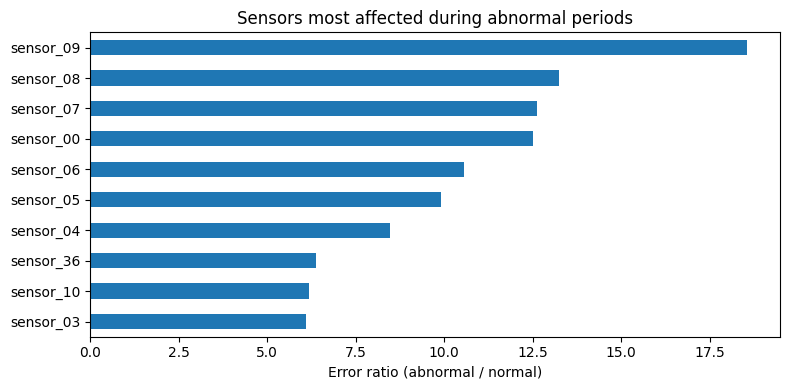

Most unusual sensors for the highest-error abnormal test window (index 12382):
sensor_41    1.8719
sensor_42    1.0689
sensor_38    1.0633
dtype: float32


In [17]:
pred_te = model.predict(X_te, batch_size=256, verbose=0)
sensor_err = np.abs(pred_te - X_te).mean(axis=1)      # shape: (windows, sensors)

ratio = sensor_err[y_te == 1].mean(axis=0) / (sensor_err[y_te == 0].mean(axis=0) + 1e-9)
top10 = pd.Series(ratio, index=sensor_cols).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
top10[::-1].plot(kind='barh')
plt.title('Sensors most affected during abnormal periods')
plt.xlabel('Error ratio (abnormal / normal)')
plt.tight_layout()
plt.show()

def top_sensors(window_index, k=3):
    s = pd.Series(sensor_err[window_index], index=sensor_cols)
    return s.sort_values(ascending=False).head(k)

worst = np.where(y_te == 1)[0][np.argmax(te_err[y_te == 1])]
print(f"Most unusual sensors for the highest-error abnormal test window (index {worst}):")
print(top_sensors(worst).round(4))

### 12.2 Does normal behaviour drift?

Version 4 suspected that the normal behaviour of the pump changes over time, but did not measure it. This diagnosis needs no model: only readings labelled NORMAL are used, so faults cannot be mistaken for drift. The normal readings are split in time into an **early** third and a **late** third. For every sensor the table reports

- **Shift (std units):** how far the mean of the late normal readings lies from the mean of the early normal readings, in standard deviations of the early readings (values beyond +/- 1 are a clear shift, beyond +/- 3 a large one),
- **Out of range (%):** the share of late normal readings outside the minimum-maximum range of the early readings. These readings are outside the range the scaler and the model have seen during training.

The plot shows the block-wise mean of the four most shifted sensors (in early standard deviations); grey bands mark blocks that contain abnormal data.

Normal readings, early third versus late third:
  sensors with |shift| > 1 std : 9 of 51
  sensors with |shift| > 3 std : 2 of 51
  median share of late readings outside the early range: 0.0%

Ten most shifted sensors:
           Shift (std units)  Out of range (%)
sensor_50              18.42            100.00
sensor_37              -3.16              0.00
sensor_34               2.51             44.04
sensor_13               2.30              0.00
sensor_48               2.06              1.38
sensor_36               2.02              0.00
sensor_35               1.93             15.07
sensor_06               1.83             40.00
sensor_23               1.02              0.08
sensor_22               0.94              0.07


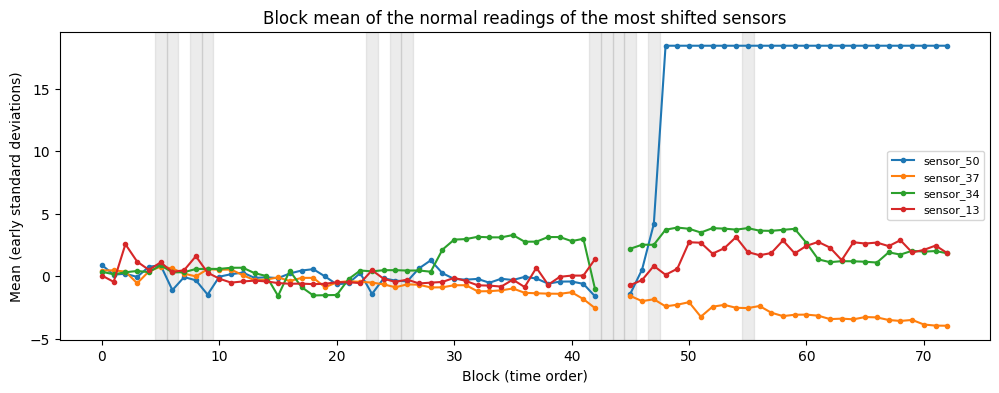

In [18]:
normal_rows = np.where(labels == 0)[0]
third = len(normal_rows) // 3
early_rows, late_rows = normal_rows[:third], normal_rows[-third:]

drift_all = sensor_drift(early_rows, late_rows)
drift_all['Abs. shift'] = drift_all['Shift (std units)'].abs()
drift_all = drift_all.sort_values('Abs. shift', ascending=False)

print("Normal readings, early third versus late third:")
print(f"  sensors with |shift| > 1 std : {(drift_all['Abs. shift'] > 1).sum()} of {N_FEATURES}")
print(f"  sensors with |shift| > 3 std : {(drift_all['Abs. shift'] > 3).sum()} of {N_FEATURES}")
print(f"  median share of late readings outside the early range: {drift_all['Out of range (%)'].median():.1f}%")
print("\nTen most shifted sensors:")
print(drift_all.drop(columns='Abs. shift').head(10).round(2))

top_idx = [sensor_cols.index(s) for s in drift_all.index[:4]]
block_mean = np.full((n_blocks, N_FEATURES), np.nan)
for b in range(n_blocks):
    rows_b = np.arange(b * B, (b + 1) * B)
    rows_b = rows_b[labels[rows_b] == 0]
    if len(rows_b) > 100:
        block_mean[b] = values[rows_b].mean(axis=0)
mu_e, sd_e = values[early_rows].mean(axis=0), values[early_rows].std(axis=0) + 1e-9
z_block = (block_mean - mu_e) / sd_e

plt.figure(figsize=(12, 4))
for j in top_idx:
    plt.plot(z_block[:, j], marker='.', label=sensor_cols[j])
for b in np.where(blk_has_abn == 1)[0]:
    plt.axvspan(b - 0.5, b + 0.5, color='grey', alpha=0.15)
plt.title('Block mean of the normal readings of the most shifted sensors')
plt.xlabel('Block (time order)')
plt.ylabel('Mean (early standard deviations)')
plt.legend(fontsize=8)
plt.show()

## 13. Block cross-validation

**Problem.** The primary test set contains only a handful of separate fault events, so its results can be a matter of luck.

**Solution.** The blocks are divided into `K_FOLDS` folds, keeping the abnormal blocks spread evenly across the folds. In turn, every fold is used as the **test** set, the next fold as the **validation** set (threshold selection) and the remaining folds for **training**. The scaler is fitted again inside every fold on training data only. After all folds have run, **every block of the dataset, and therefore every fault event, has been tested exactly once**, and the spread over folds shows how stable the results are.

One LSTM autoencoder (first seed) and one Isolation Forest are trained per fold. The event-level columns use the label-free threshold. The columns `BROKEN windows` and `BROKEN detected` count the windows containing a BROKEN reading and how many of them raised an alarm (Section 11.3).

In [19]:
def make_folds(k, seed=SEED):
    """Spread normal and abnormal blocks evenly over k folds."""
    r = np.random.default_rng(seed)
    folds = [[] for _ in range(k)]
    j = 0
    for ids in (np.where(blk_has_abn == 0)[0], np.where(blk_has_abn == 1)[0]):
        for b in r.permutation(ids):
            folds[j % k].append(int(b))
            j += 1
    return folds

folds = make_folds(K_FOLDS)
cv_rows = []
for k in range(K_FOLDS):
    te_b, va_b = folds[k], folds[(k + 1) % K_FOLDS]
    tr_b = [b for j, f in enumerate(folds) if j not in (k, (k + 1) % K_FOLDS) for b in f]
    d = prepare(tr_b, va_b, te_b)
    if d['y_va'].sum() == 0 or d['y_te'].sum() == 0:
        print(f"Fold {k + 1}: skipped (no abnormal windows in validation or test)")
        continue

    Xn_tr, Xn_va = d['X_tr'][d['y_tr'] == 0], d['X_va'][d['y_va'] == 0]

    m_k, _, secs = train_ae(lambda: build_model(W, N_FEATURES), Xn_tr, Xn_va, SEEDS[0])
    va_s, te_s = get_err(m_k, d['X_va']), get_err(m_k, d['X_te'])
    r_l = summarize('LSTM autoencoder', d['y_va'], va_s, d['y_te'], te_s)
    al_l = te_s > r_l['LF Threshold']
    _, ev_l = event_report(d['y_te'], al_l, d['g_te'])

    Fk_tr = window_features(Xn_tr)
    iso_k = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(Fk_tr)
    va_i = -iso_k.score_samples(window_features(d['X_va']))
    te_i = -iso_k.score_samples(window_features(d['X_te']))
    r_i = summarize('Isolation Forest', d['y_va'], va_i, d['y_te'], te_i)
    al_i = te_i > r_i['LF Threshold']
    _, ev_i = event_report(d['y_te'], al_i, d['g_te'])

    n_brk = int(d['b_te'].sum())
    for r_, ev_, al_ in [(r_l, ev_l, al_l), (r_i, ev_i, al_i)]:
        cv_rows.append({'Fold': k + 1, 'Family': r_['Model'], 'Test abnormal %': round(d['y_te'].mean() * 100, 1),
                        **result_fields(r_, ev_),
                        'BROKEN windows': n_brk, 'BROKEN detected': int(al_[d['b_te']].sum())})
    print(f"Fold {k + 1}/{K_FOLDS} done ({secs:.0f} s training)")
    del d, m_k

cv_df = pd.DataFrame(cv_rows)
print()
print(cv_df.round(3).to_string(index=False))

CV_METRICS = ['AUC', 'AP', 'Recall@FPR', 'F1', 'LF Precision', 'LF Recall', 'LF F1']
cv_summary = cv_df.groupby('Family')[CV_METRICS].agg(['mean', 'std']).round(3)
print("\nMean and standard deviation over folds:")
print(cv_summary.T.to_string())

pooled = cv_df.groupby('Family')[['Events', 'Detected', 'False-alarm episodes', 'BROKEN windows', 'BROKEN detected']].sum()
print("\nAll folds together (every fault event tested once; event-level columns use the label-free threshold):")
print(pooled)

Fold 1/5 done (153 s training)
Fold 2/5 done (151 s training)
Fold 3/5 done (156 s training)
Fold 4/5 done (152 s training)
Fold 5/5 done (163 s training)

 Fold           Family  Test abnormal %   AUC    AP  Recall@FPR  Precision  Recall    F1  LF Precision  LF Recall  LF F1  Events  Detected  False-alarm episodes  BROKEN windows  BROKEN detected
    1 LSTM autoencoder             11.1 0.993 0.952       0.825      0.854   0.833 0.843         0.917      0.824  0.868       3         3                     9              10                5
    1 Isolation Forest             11.1 0.988 0.858       0.751      0.773   0.890 0.827         0.762      0.917  0.833       3         3                    20              10                1
    2 LSTM autoencoder              7.7 0.993 0.886       0.773      0.968   0.599 0.740         0.873      0.771  0.819       3         3                     7              20               13
    2 Isolation Forest              7.7 0.997 0.910       0.955     

## 14. Forward-chaining evaluation (training on the past, testing on the future)

**Problem.** The block split (and block cross-validation) mixes time periods: a block from the future can be used for training and a block from the past for testing. A deployed system, however, only ever sees data from *after* its training period, and the normal behaviour of a pump drifts over time. In version 4 the AUC of the LSTM dropped in this setting (0.63 and 0.77) while the Isolation Forest stayed at 0.99, which points to drift, but other explanations (a scaler fitted on an old value range, very few events) are possible.

**Solution.** For every cutoff in `FC_CUTOFFS`, the model is trained only on the blocks **before** the cutoff. The following `FC_VAL_FRAC` of the blocks are used for validation (threshold selection) and the next `FC_TEST_FRAC` of the blocks for testing, so the model is always tested on a **later** period than the one it learned from. A step is skipped if its validation or test period contains no abnormal windows.

**Variants.** To find out whether drift is the cause, and what helps against it, the following variants are trained on exactly the same blocks (all use the label-free threshold for the event columns):

| Variant | What changes | Idea |
|---|---|---|
| **LSTM (baseline)** | Min-max scaler, all sensors | Same as the main model |
| **LSTM + robust scaler** | Median / interquartile range scaling, clipped to +/- `SCALE_CLIP` | Less sensitive to a shifted value range and to outliers |
| **LSTM + stable sensors** | Only sensors whose normal mean moves by less than `STABLE_Z` standard deviations between the training and the validation blocks (selected from normal readings of these two periods only; the test period is never used) | If the AUC recovers, the drifting sensors were the problem |
| **LSTM + first differences** | Input is the change between consecutive readings (robust scaler) | Removes slow drift, keeps short-term behaviour |
| **LSTM (adaptive)** | Baseline scores divided by the lower quartile (`ADAPT_Q`) of the previous `ROLL_WINDOWS` scores (computed causally, no retraining) | Lets the threshold follow a slowly rising error level; assumes that fewer than three quarters of the recent windows are abnormal |
| **LSTM + Isolation Forest** | Standardised average of baseline LSTM and Isolation Forest | Combines sequence-based and summary-based detection |
| **Isolation Forest** | Summary statistics per window | Reference |

**Diagnostic columns.** `Drifted sensors (%)`: share of sensors whose normal readings in the validation and test period are shifted by more than 1 training standard deviation (Section 12.2). `Normal-error ratio`: median reconstruction error of *normal* test windows divided by that of the normal training windows; a value clearly above 1 means that the model reconstructs normal behaviour of the later period worse than what it was trained on.

In [20]:
VARIANT_SPECS = {
    'LSTM (baseline)':          dict(scaler='minmax'),
    'LSTM + robust scaler':     dict(scaler='robust'),
    'LSTM + stable sensors':    dict(scaler='minmax', stable=True),
    'LSTM + first differences': dict(scaler='robust', diff=True),
}

fc_rows = []
for cut in FC_CUTOFFS:
    a = int(n_blocks * cut)
    b = a + int(n_blocks * FC_VAL_FRAC)
    c = min(b + int(n_blocks * FC_TEST_FRAC), n_blocks)
    train_b, val_b, test_b = list(range(0, a)), list(range(a, b)), list(range(b, c))
    label = f"train blocks 0-{a - 1}, test blocks {b}-{c - 1}"

    d0 = prepare(train_b, val_b, test_b)
    if d0['y_va'].sum() == 0 or d0['y_te'].sum() == 0:
        print(f"Cutoff {cut}: skipped ({label}): no abnormal windows in validation or test")
        continue
    y_v, y_t, g_t = d0['y_va'], d0['y_te'], d0['g_te']

    # drift between the training period and the later periods (normal readings only)
    later = block_rows(val_b + test_b)
    later = later[labels[later] == 0]
    drift_pct = float((sensor_drift(d0['fit_rows'], later)['Shift (std units)'].abs() > 1).mean() * 100)

    # LSTM variants
    step = {}          # name -> (validation scores, test scores)
    extra = {}         # name -> normal-error ratio
    secs_total = 0.0
    for name in FC_VARIANTS:
        spec = dict(VARIANT_SPECS[name])
        if spec.pop('stable', False):
            spec['sensors'] = stable_sensor_idx(train_b, val_b)
        d = d0 if spec == {'scaler': 'minmax'} else prepare(train_b, val_b, test_b, **spec)
        n_feat = d['X_tr'].shape[2]
        Xn_tr, Xn_va = d['X_tr'][d['y_tr'] == 0], d['X_va'][d['y_va'] == 0]
        m_f, _, secs = train_ae(lambda: build_model(W, n_feat), Xn_tr, Xn_va, SEEDS[0])
        secs_total += secs
        tr_s, va_s, te_s = get_err(m_f, Xn_tr), get_err(m_f, d['X_va']), get_err(m_f, d['X_te'])
        step[name] = (va_s, te_s)
        extra[name] = float(np.median(te_s[y_t == 0]) / (np.median(tr_s) + 1e-12))
        if name == 'LSTM (baseline)':
            base_tr, base_va, base_te = tr_s, va_s, te_s
        if d is not d0:
            del d
        del m_f

    # models that reuse the baseline scores or need no neural network
    Xn_tr0 = d0['X_tr'][d0['y_tr'] == 0]
    iso_f = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(window_features(Xn_tr0))
    iso_sc = (-iso_f.score_samples(window_features(d0['X_va'])), -iso_f.score_samples(window_features(d0['X_te'])))
    if 'LSTM (baseline)' in step:
        step['LSTM (adaptive)'] = (adaptive_scores(base_va, base_tr), adaptive_scores(base_te, base_va))
        step['LSTM + Isolation Forest'] = standardised_average([step['LSTM (baseline)'], iso_sc], y_v)
    step['Isolation Forest'] = iso_sc

    for name, (va_s, te_s) in step.items():
        r_ = summarize(name, y_v, va_s, y_t, te_s)
        _, ev_ = event_report(y_t, te_s > r_['LF Threshold'], g_t)
        fc_rows.append({'Cutoff': cut, 'Period': label, 'Family': name,
                        'Test abnormal %': round(y_t.mean() * 100, 1),
                        'Drifted sensors (%)': round(drift_pct, 1),
                        'Normal-error ratio': extra.get(name, np.nan),
                        **result_fields(r_, ev_)})
    print(f"Cutoff {cut} done ({secs_total:.0f} s training in total)")
    del d0

fc_df = pd.DataFrame(fc_rows)
SHOW = ['Cutoff', 'Family', 'Test abnormal %', 'Drifted sensors (%)', 'Normal-error ratio',
        'AUC', 'AP', 'Recall@FPR', 'F1', 'LF F1', 'Events', 'Detected', 'False-alarm episodes']
if len(fc_df):
    print()
    print(fc_df[SHOW].round(3).to_string(index=False))
    print("\nMean over forward-chaining steps:")
    print(fc_df.groupby('Family', sort=False)[['AUC', 'AP', 'Recall@FPR', 'F1', 'LF F1']].mean().round(3))

Cutoff 0.35 done (385 s training in total)
Cutoff 0.45: skipped (train blocks 0-31, test blocks 42-51): no abnormal windows in validation or test
Cutoff 0.5 done (505 s training in total)

 Cutoff                   Family  Test abnormal %  Drifted sensors (%)  Normal-error ratio   AUC    AP  Recall@FPR    F1  LF F1  Events  Detected  False-alarm episodes
   0.35          LSTM (baseline)             23.2                 11.8               7.826 0.977 0.932       0.754 0.494  0.488       3         3                    19
   0.35     LSTM + robust scaler             23.2                 11.8               3.702 0.942 0.779       0.035 0.715  0.707       3         3                    42
   0.35    LSTM + stable sensors             23.2                 11.8               7.280 0.983 0.949       0.752 0.445  0.444       3         3                    10
   0.35 LSTM + first differences             23.2                 11.8               1.104 0.090 0.132       0.000 0.000  0.003       3    

### 14.1 How to read the forward-chaining results

The tables answer three separate questions. They should be read together, and with care: each step contains only a few fault events, and every variant is trained once.

| Observation | What it suggests |
|---|---|
| `Drifted sensors (%)` is high and `Normal-error ratio` is clearly above 1 | The model reconstructs the later normal behaviour worse than the training period: drift affects the LSTM |
| The stable-sensor, robust-scaler or first-difference variant has a clearly higher AUC / AP than the baseline | The loss is (at least partly) caused by drifting inputs, and the corresponding measure helps |
| No variant improves on the baseline, but the Isolation Forest stays high | The drift explanation is not enough; the summary-statistics representation is the more robust one on this dataset, and the hybrid or the Isolation Forest should be preferred |
| The adaptive variant has a higher `LF F1` or lower `False-alarm episodes` than the baseline at similar AUC | The ranking of windows was fine; the fixed threshold was the problem |
| AUC and AP are high for all variants but `LF F1` is low | The scores separate the classes, but the share of abnormal windows is so small (`Test abnormal %`) that precision stays low: this is a property of the test period, not necessarily of the model |

If a variant that removes the drifting sensors loses AUC, this can also mean that the removed sensors carried the fault signal; stable sensors are chosen without looking at the test period, but not without regard to what the faults look like.

## 15. Scalability

Two practical questions are examined: how the approach behaves when it is trained on more or less data, and how fast it can score new data.

### 15.1 Scalability with training data size

The LSTM autoencoder (first seed) is trained on a random subset of the normal training windows (the fractions in `TRAIN_FRACTIONS`) and compared with the full training set from Section 7. For every size, the number of training windows, the epochs run, the training time and the test performance are recorded. This shows how the training cost grows with data and whether more data keeps improving the results. Each size is trained once, so small differences should be read together with the run-to-run variation from Section 8. AUC and AP do not depend on a threshold and are the more reliable columns; `LF F1` uses the label-free threshold, `F1` the tuned one.

Training data  Training windows  Epochs run  Training time (s)   AUC    AP    F1  LF F1
          25%              9292          30                 58 0.980 0.730 0.696  0.676
          50%             18584          30                 92 0.985 0.745 0.778  0.786
         100%             37169          30                147 0.981 0.732 0.686  0.705


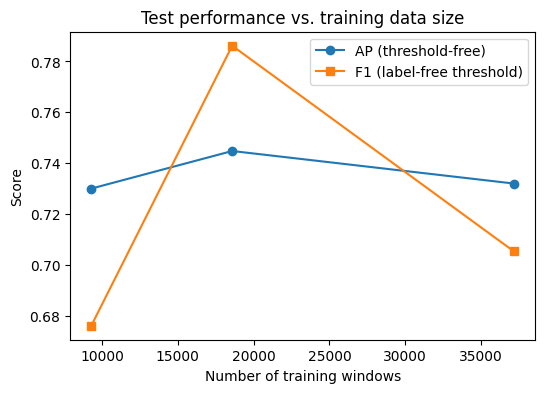

In [21]:
sub_rng = np.random.default_rng(SEED)
scal_rows = []

for frac in TRAIN_FRACTIONS:
    sel = sub_rng.choice(len(X_tr_n), size=int(len(X_tr_n) * frac), replace=False)
    m_f, h, t_train = train_ae(lambda: build_model(W, N_FEATURES), X_tr_n[sel], X_va_n, SEEDS[0])
    r = summarize('', y_va, get_err(m_f, X_va), y_te, get_err(m_f, X_te))
    scal_rows.append({'Training data': f'{int(frac * 100)}%', 'Training windows': len(sel),
                      'Epochs run': len(h.history['loss']), 'Training time (s)': round(t_train),
                      'AUC': r['AUC'], 'AP': r['AP'], 'F1': r['F1'], 'LF F1': r['LF F1']})

ref = members[0]
scal_rows.append({'Training data': '100%', 'Training windows': len(X_tr_n),
                  'Epochs run': len(ref['history'].history['loss']), 'Training time (s)': round(ref['seconds']),
                  'AUC': ref['result']['AUC'], 'AP': ref['result']['AP'],
                  'F1': ref['result']['F1'], 'LF F1': ref['result']['LF F1']})

scal_df = pd.DataFrame(scal_rows)
print(scal_df.round(3).to_string(index=False))

plt.figure(figsize=(6, 4))
plt.plot(scal_df['Training windows'], scal_df['AP'], marker='o', label='AP (threshold-free)')
plt.plot(scal_df['Training windows'], scal_df['LF F1'], marker='s', label='F1 (label-free threshold)')
plt.title('Test performance vs. training data size')
plt.xlabel('Number of training windows')
plt.ylabel('Score')
plt.legend()
plt.show()

### 15.2 Inference speed

For deployment, what matters is how quickly new data can be scored. This cell measures:
- the time needed to score batches of windows of increasing size (best of three runs) and the resulting throughput in windows per second, for the selected LSTM model and for the Isolation Forest (including its feature computation),
- the average latency of scoring one single window with the LSTM.

Timings depend on the hardware (CPU or GPU) of the runtime, so they are indicative only.

In [22]:
def best_time(fn, repeats=3):
    times = []
    for _ in range(repeats):
        t0 = time.time()
        fn()
        times.append(time.time() - t0)
    return min(times)

get_err(model, X_te[:256])      # warm-up so that start-up cost is not measured

inf_rows = []
for size in [100, 1000, 5000, len(X_te)]:
    if size > len(X_te):
        continue
    Xs = X_te[:size]
    t_l = best_time(lambda: get_err(model, Xs))
    t_i = best_time(lambda: iso.score_samples(window_features(Xs)))
    inf_rows.append({'Windows': size,
                     'LSTM (s)': round(t_l, 3), 'LSTM (windows/s)': int(size / t_l),
                     'Isolation Forest (s)': round(t_i, 3), 'Isolation Forest (windows/s)': int(size / t_i)})
print(pd.DataFrame(inf_rows).drop_duplicates('Windows').to_string(index=False))

x1 = X_te[:1]
model.predict(x1, verbose=0)
t0 = time.time()
for _ in range(20):
    model.predict(x1, verbose=0)
print("\nLSTM latency for a single window: %.1f ms" % ((time.time() - t0) / 20 * 1000))

 Windows  LSTM (s)  LSTM (windows/s)  Isolation Forest (s)  Isolation Forest (windows/s)
     100     0.075              1332                 0.014                          7366
    1000     0.099             10122                 0.032                         31509
    5000     0.284             17587                 0.107                         46692
   17838     0.928             19212                 0.342                         52128

LSTM latency for a single window: 76.1 ms


## 16. Summary and limitations

The table combines the main results of this notebook. All figures refer to the abnormal class on held-out test data. `Precision`, `Recall` and `F1` use the threshold tuned on validation, `LF F1` the label-free threshold, `AUC`, `AP` and `Recall@FPR` need no threshold. Rows marked "cross-validation" and "forward chaining" are averages over several test sets and are therefore the most reliable numbers; the forward-chaining rows also contain the drift-oriented variants of Section 14.

In [23]:
SUMMARY_COLS = ['AUC', 'AP', 'Recall@FPR', 'Precision', 'Recall', 'F1', 'LF F1']
rows = [{'Setup': 'First version (whole dataset, no proper split)', 'Precision': 0.08, 'Recall': 0.99, 'F1': 0.16}]
for rec in comparison_df.to_dict('records'):
    rows.append({'Setup': rec['Model'] + ' - primary test set', **{c: rec[c] for c in SUMMARY_COLS}})
if len(cv_df):
    for fam, g in cv_df.groupby('Family'):
        rows.append({'Setup': f'{fam} - {K_FOLDS}-fold block cross-validation (mean)', **g[SUMMARY_COLS].mean().to_dict()})
if len(fc_df):
    for fam, g in fc_df.groupby('Family', sort=False):
        rows.append({'Setup': f'{fam} - forward chaining (mean of {len(g)} steps)', **g[SUMMARY_COLS].mean().to_dict()})

final_table = pd.DataFrame(rows)[['Setup'] + SUMMARY_COLS].round(3)
print(final_table.to_string(index=False))
print()
print("Event-level, primary test set (LSTM ensemble, label-free threshold):", ev_ens_sum)
print("Event-level, all cross-validation folds (label-free threshold):")
print(pooled)

                                                        Setup   AUC    AP  Recall@FPR  Precision  Recall    F1  LF F1
               First version (whole dataset, no proper split)   NaN   NaN         NaN      0.080   0.990 0.160    NaN
         LSTM autoencoder (mean of 3 runs) - primary test set 0.982 0.726       0.506      0.658   0.829 0.728  0.749
                             LSTM ensemble - primary test set 0.982 0.726       0.513      0.663   0.975 0.789  0.783
                          Isolation Forest - primary test set 0.942 0.491       0.131      0.393   0.900 0.547  0.554
                  PCA reconstruction error - primary test set 0.976 0.714       0.378      0.600   0.824 0.694  0.575
                             One-Class SVM - primary test set 0.983 0.733       0.439      0.613   1.000 0.760  0.799
                         Dense autoencoder - primary test set 0.982 0.804       0.527      0.614   0.795 0.693  0.714
                           GRU autoencoder - primary tes

### Diagnostics for the report

The next cell prints the numbers needed to decide which explanation of the version 4 results is supported: how unstable the threshold is, whether the threshold-free metrics are stable, and whether the drift-oriented variants help. It only reports numbers; the conclusions must be drawn from them after the run.

In [24]:
if len(cv_df):
    print("1. Stability of the decision over the block cross-validation folds")
    print("   (standard deviation of F1: tuned threshold versus label-free threshold)")
    print(cv_df.groupby('Family')[['F1', 'LF F1']].std().round(3).to_string())
    print("\n   Mean of the threshold-free metrics over the folds:")
    print(cv_df.groupby('Family')[['AUC', 'AP', 'Recall@FPR']].mean().round(3).to_string())

if len(fc_df):
    print("\n2. Forward chaining: threshold-free metrics per variant (rows = cutoff)")
    order = list(fc_df['Family'].unique())
    for metric in ['AUC', 'AP']:
        print(f"\n   {metric}")
        print(fc_df.pivot_table(index='Cutoff', columns='Family', values=metric)[order].round(3).to_string())
    print("\n   Normal-error ratio (median error of normal test windows / normal training windows)")
    print(fc_df.pivot_table(index='Cutoff', columns='Family', values='Normal-error ratio')
          .dropna(axis=1, how='all').round(2).to_string())
    print("\n   Drifted sensors (%) per step:", fc_df.groupby('Cutoff')['Drifted sensors (%)'].first().to_dict())

1. Stability of the decision over the block cross-validation folds
   (standard deviation of F1: tuned threshold versus label-free threshold)
                     F1  LF F1
Family                        
Isolation Forest  0.266  0.298
LSTM autoencoder  0.192  0.334

   Mean of the threshold-free metrics over the folds:
                    AUC     AP  Recall@FPR
Family                                    
Isolation Forest  0.989  0.758       0.740
LSTM autoencoder  0.987  0.769       0.696

2. Forward chaining: threshold-free metrics per variant (rows = cutoff)

   AUC
Family  LSTM (baseline)  LSTM + robust scaler  LSTM + stable sensors  LSTM + first differences  LSTM (adaptive)  LSTM + Isolation Forest  Isolation Forest
Cutoff                                                                                                                                                    
0.35              0.977                 0.942                  0.983                     0.090            0.539     

### How the main limitations were addressed

| Limitation | Measure | Status |
|---|---|---|
| Very few fault events in a single test set | Block cross-validation: every event is tested once (Section 13); block bootstrap intervals (Section 10.2) | Addressed within this dataset |
| Block split does not look into the future | Forward-chaining evaluation (Section 14) | Addressed within this dataset |
| Results differ between training runs | Ensemble, mean and standard deviation over runs (Sections 7-8) | Addressed |
| Only one baseline | Six comparison methods (Section 10) | Addressed |
| Threshold needs fault labels and is unstable | Label-free threshold from normal validation windows (Sections 6, 8, 9) | Measured in Sections 13 and 14 |
| F1 depends on the share of abnormal windows | AP and Recall@FPR reported next to F1 (Section 6) | Addressed |
| Isolated false alarms | Persistence rule (Section 11.2) | Measured on the primary test set |
| Drift suspected but not shown | Drift diagnosis (Section 12.2) and drift-oriented variants (Section 14) | Measured; the conclusion depends on the results of Sections 12.2 and 14 |
| Alarm smoothing | Averaging the error over consecutive windows gave no improvement in earlier experiments and was dropped; replaced by the persistence rule | Negative result (earlier version) |

### Remaining limitations

- **Very few real breakdowns.** The dataset contains only 7 BROKEN readings, so performance on genuine breakdowns cannot be assessed separately from recovery periods. The system detects abnormal states in general.
- **A single machine and public benchmark data.** All evaluations use one pump and one dataset, so generalisation to other machines or to a live industrial deployment is untested. This can only be addressed with additional data.
- **Event definition.** Events longer than one block are cut into several events, and a window counts as abnormal if any of its rows is abnormal.
- **Label-free does not mean assumption-free.** The label-free threshold needs a period that is known to be healthy, and it fixes the false-alarm rate on normal windows (about `100 - THRESHOLD_Q` percent) but not the precision, which also depends on how often faults occur. The stable-sensor selection and the adaptive normalisation also use this knowledge or assumption (fewer than three quarters of the recent windows are abnormal).
- **Persistence setting fixed in advance.** `PERSIST_K` of `PERSIST_M` was not tuned; other values trade delay against false alarms (Section 11.2).
- **Limited drift handling.** Forward chaining shows how the model behaves on later periods, and the variants of Section 14 test measures against drift, but the deployed model is not retrained automatically. A deployed system would need periodic retraining or recalibration, triggered for example by the drift monitor values stored in `config.json`.
- **Single runs per variant.** The variants of Section 14 and the baselines of Section 10 are trained once per step, and every forward-chaining step contains only a few events; small differences between variants should not be over-interpreted.
- **Baseline scope.** Further deep anomaly detectors (for example transformer-based models) were not compared.

### Future work

- Test on a second pump or machine dataset, and on live data.
- Retrain or fine-tune periodically on recent normal data, and use the drift monitor to decide when.
- Deploy the saved model, scaler and configuration (Section 9) behind an API that writes anomaly scores and the most unusual sensors (Section 12) to a database, with a mobile dashboard for alerts.